# 18 — Risk prices, covariances and premium signs

Inspect the saved **full S4** model shown in notebook 17 and the final **FX-only** branch, for
USD/EUR investors and both retained covariance models. Use the frozen **2026-11-13** snapshot
(321 months, January 2000–September 2026), corrected FX means and zero equity alphas.
This notebook reads saved estimates: no fetching, fitting or changes to previous inputs.

For each equity and each separate factor,
$$P_{ik,t}=\lambda_{k,t} H_{ik,t},\qquad
\operatorname{sign}(P_{ik,t})=\operatorname{sign}(\lambda_{k,t})\operatorname{sign}(H_{ik,t}).$$
The local Own term uses $H_{ii,t}$, a **positive variance**. World/FX exposures are conditional
innovation covariances from the fitted system, rather than raw full-sample return covariances.
All returns in that system are scaled by 100: exposures are in squared percentage points,
contributions in **monthly log percentage points**, and risk-price coefficients use the matching scale.
The price already includes the engine's 0.01 scale; do not multiply by 0.01 again.

Positive HUF FX means HUF appreciation against the investor currency. Other FX means EUR
appreciation against USD for a USD investor, and USD appreciation against EUR for a EUR investor.
Converted Hungarian equity returns themselves include HUF conversion, so a positive HUF covariance
is not independent evidence of a causal currency effect. Factor contributions depend on the chosen
FX basis. Reversing one factor's sign consistently reverses both its price and covariance, preserving
their product. USD/EUR models also use different cash proxies and conditioners.

Inspect each FX product separately. The combined Currency line is their **sum**, so it has no single
risk-price/covariance sign pair. A fitted sign does not establish statistical significance or predict
realized returns. Average contributions are averages of monthly products, not products of averages.


In [1]:
SHOW_SPEC = "S4"     # "S4": full model in the charts; "FX": constant world/local prices
SHOW_ASSET = "HU"    # "HU" or "US"; all cases are calculated and exported either way

from pathlib import Path
from io import BytesIO
import hashlib, json, os, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

assert SHOW_SPEC in ["S4", "FX"] and SHOW_ASSET in ["HU", "US"]
LOCK = json.loads((ROOT / "research_synthesis_inputs.json").read_text())
OUT = ROOT / "output/18_risk_price_covariance_signs/fixed_2026-11-13"
OUT.mkdir(parents=True, exist_ok=True)
used = {}
def read(path):
    relative = path.relative_to(ROOT).as_posix()
    raw = path.read_bytes()
    digest = hashlib.sha256(raw).hexdigest()
    if digest != LOCK["files"][relative]:
        raise ValueError(f"Frozen research input changed: {relative}")
    used[relative] = digest
    return raw

data = pd.read_csv(BytesIO(read(ROOT / LOCK["snapshot"] / "dataset.csv")), index_col=0)
months = pd.PeriodIndex(data.index, freq="M")
assert len(months) == 321 and str(months[0]) == "2000-01" and str(months[-1]) == "2026-09"
print("Python:", sys.executable)
print(f"Frozen sample: {months[0]} to {months[-1]}, {len(months)} months")


Python: /Users/lajosgalambos/miniconda3/bin/python
Frozen sample: 2000-01 to 2026-09, 321 months


## Reconstruct each product and check the saved means

The saved conditional covariance matrices and price-design parameters are pinned by the research
input lock. Check every factor's sign identity, every equity decomposition, all five saved pricing
means, positive variances and the covariance matrices' positive definiteness. Signs use unrounded
numbers; display rounding never determines a sign.


In [2]:
rows, audits = [], []
for spec, stage in [("S4", 12), ("FX", 13)]:
    source = ROOT / LOCK["sources"][str(stage)]["root"]
    manifest = json.loads(read(source / "estimation_manifest.json"))
    assert manifest["source_dataset_sha256"] == LOCK["dataset_sha256"]
    for currency in ["USD", "EUR"]:
        for model in ["scalar11", "grouped21"]:
            key = f"{currency}_{model}_{spec}"
            with np.load(BytesIO(read(source / f"parameters_{key}.npz")), allow_pickle=False) as saved:
                p = {name: saved[name].copy() for name in saved.files}
            H = p["H"]
            assert H.shape == (321, 5, 5) and np.isfinite(H).all()
            np.testing.assert_allclose(H, H.transpose(0, 2, 1), atol=1e-12)
            assert np.linalg.eigvalsh(H).min() > 0
            assert np.array_equal(p["equity_alphas"], np.zeros(3))
            z = {}
            for factor in ["W", "H", "O", "L"]:
                design = pd.read_csv(BytesIO(read(source / f"design_{key}_{factor}.csv")),
                                     index_col=0, float_precision="round_trip")
                assert pd.PeriodIndex(design.index, freq="M").equals(months)
                z[factor] = design.to_numpy()
            w = 5 + z["W"].shape[1] - 1
            h = w + z["H"].shape[1] - 1
            o = h + z["O"].shape[1] - 1
            indices = {"W": np.r_[0, np.arange(5, w)], "H": np.r_[3, np.arange(w, h)],
                       "O": np.r_[4, np.arange(h, o)],
                       "L": np.r_[2, np.arange(o, o + z["L"].shape[1] - 1)]}
            price = {factor: .01 * (z[factor] @ p["theta"][indices[factor]]) for factor in z}
            if spec == "FX":
                assert np.ptp(price["W"]) == np.ptp(price["L"]) == 0
            fitted = sum(price[f][:, None] * H[:, :, j] for f, j in [("W", 0), ("H", 3), ("O", 4)])
            fitted[:, 1] += .01 * p["theta"][1] * H[:, 1, 1]
            fitted[:, 2] += price["L"] * H[:, 2, 2]
            np.testing.assert_allclose(fitted, p["mu"], atol=1e-10, rtol=1e-11)
            for asset, i in [("HU", 2), ("US", 1)]:
                parts = []
                for component, factor, j in [("World", "W", 0), ("HUF FX", "H", 3),
                                              ("Other FX", "O", 4), ("Own", "L", i)]:
                    lam = (np.full(len(months), .01 * p["theta"][1])
                           if asset == "US" and component == "Own" else price[factor])
                    exposure = H[:, i, j]
                    contribution = lam * exposure
                    signs = np.sign(lam) * np.sign(exposure)
                    np.testing.assert_array_equal(np.sign(contribution), signs)
                    parts.append(contribution)
                    rows.append(pd.DataFrame({"month": months.astype(str), "specification": spec,
                        "perspective": currency, "covariance_model": model, "asset": asset,
                        "component": component, "price": lam, "exposure": exposure,
                        "contribution": contribution, "price_sign": np.sign(lam).astype(int),
                        "exposure_sign": np.sign(exposure).astype(int),
                        "contribution_sign": np.sign(contribution).astype(int)}))
                error = np.max(np.abs(np.sum(parts, axis=0) - p["mu"][:, i]))
                np.testing.assert_allclose(np.sum(parts, axis=0), p["mu"][:, i], atol=1e-10, rtol=1e-11)
                audits.append({"specification": spec, "perspective": currency, "covariance_model": model,
                               "asset": asset, "months": len(months), "max_mean_error": error,
                               "minimum_H_eigenvalue": float(np.linalg.eigvalsh(H).min()),
                               "sign_mismatches": 0})

terms = pd.concat(rows, ignore_index=True)
audit = pd.DataFrame(audits)
assert len(terms) == 8 * 2 * 4 * 321
terms.to_csv(OUT / "monthly_terms.csv", index=False)
audit.to_csv(OUT / "identity_audit.csv", index=False)
display(audit)
print(f"PASS: {len(terms):,} factor-month products; no sign mismatches; all pricing means reproduced.")


,specification,perspective,covariance_model,asset,months,max_mean_error,minimum_H_eigenvalue,sign_mismatches
0,S4,USD,scalar11,HU,321,3.552714e-15,0.365099,0
1,S4,USD,scalar11,US,321,8.881784e-16,0.365099,0
2,S4,USD,grouped21,HU,321,2.220446e-15,0.335898,0
3,S4,USD,grouped21,US,321,8.881784e-16,0.335898,0
4,S4,EUR,scalar11,HU,321,1.776357e-15,0.378665,0
5,S4,EUR,scalar11,US,321,5.551115e-16,0.378665,0
6,S4,EUR,grouped21,HU,321,9.992007e-16,0.362529,0
7,S4,EUR,grouped21,US,321,4.440892e-16,0.362529,0
8,FX,USD,scalar11,HU,321,3.552714e-15,0.364102,0
9,FX,USD,scalar11,US,321,1.776357e-15,0.364102,0


PASS: 20,544 factor-month products; no sign mismatches; all pricing means reproduced.


## Prices, exposures and contributions over time

Each row is a separate product; the columns show its two inputs and the resulting premium.
Solid and dashed lines are the two retained covariance models. Column scales have different units.
The Own exposure is variance. Read the other-FX label relative to the investor currency.


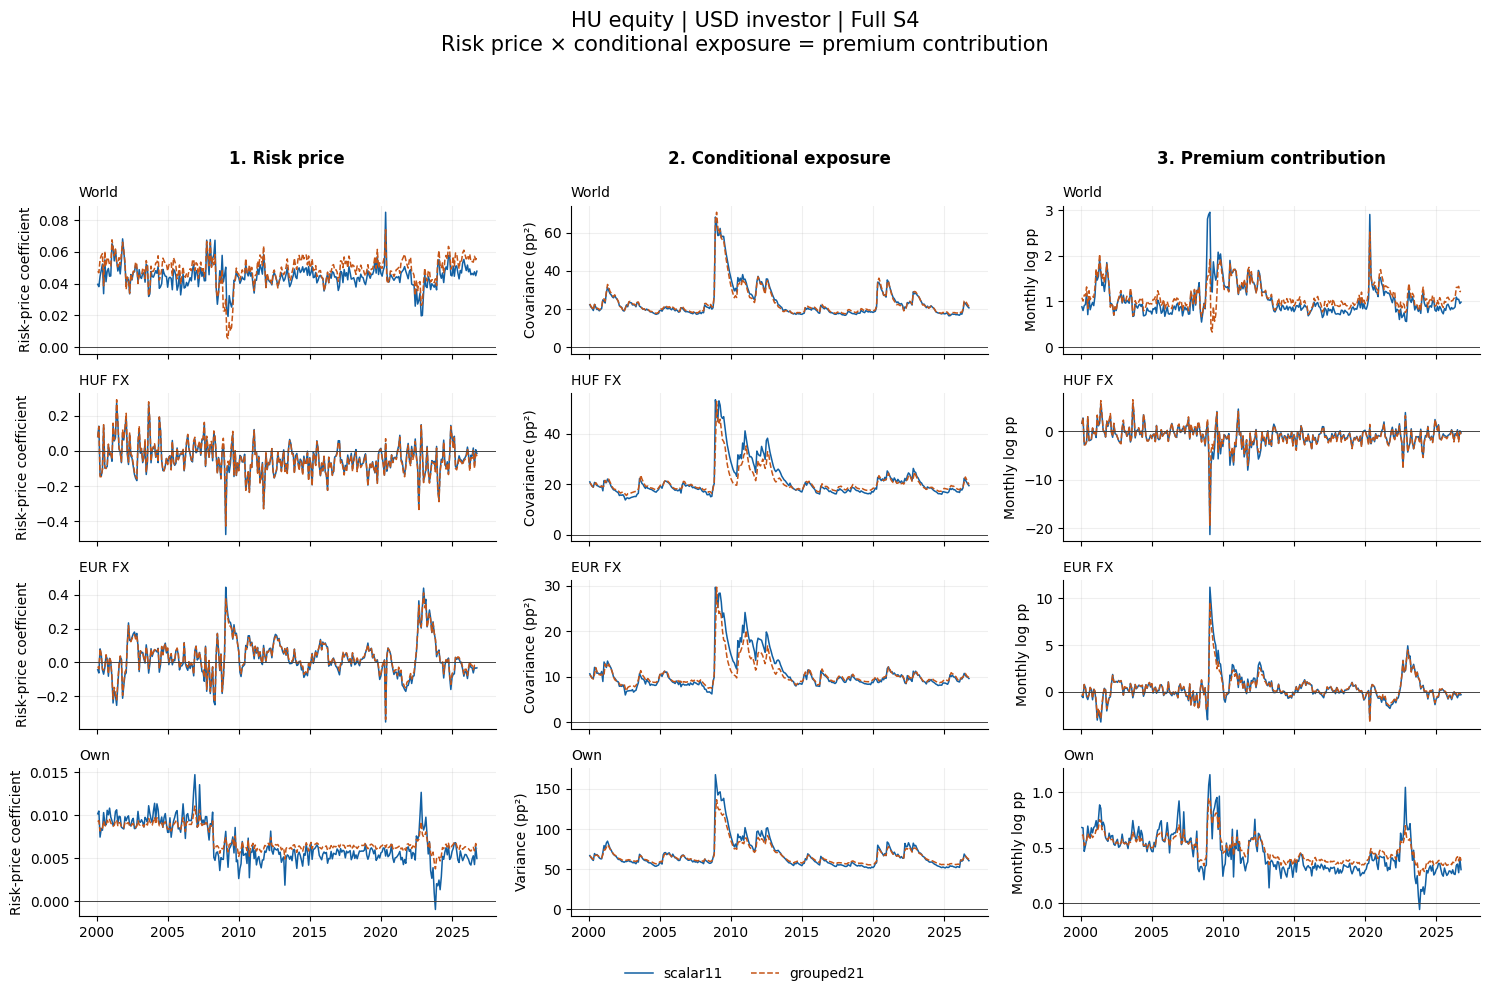

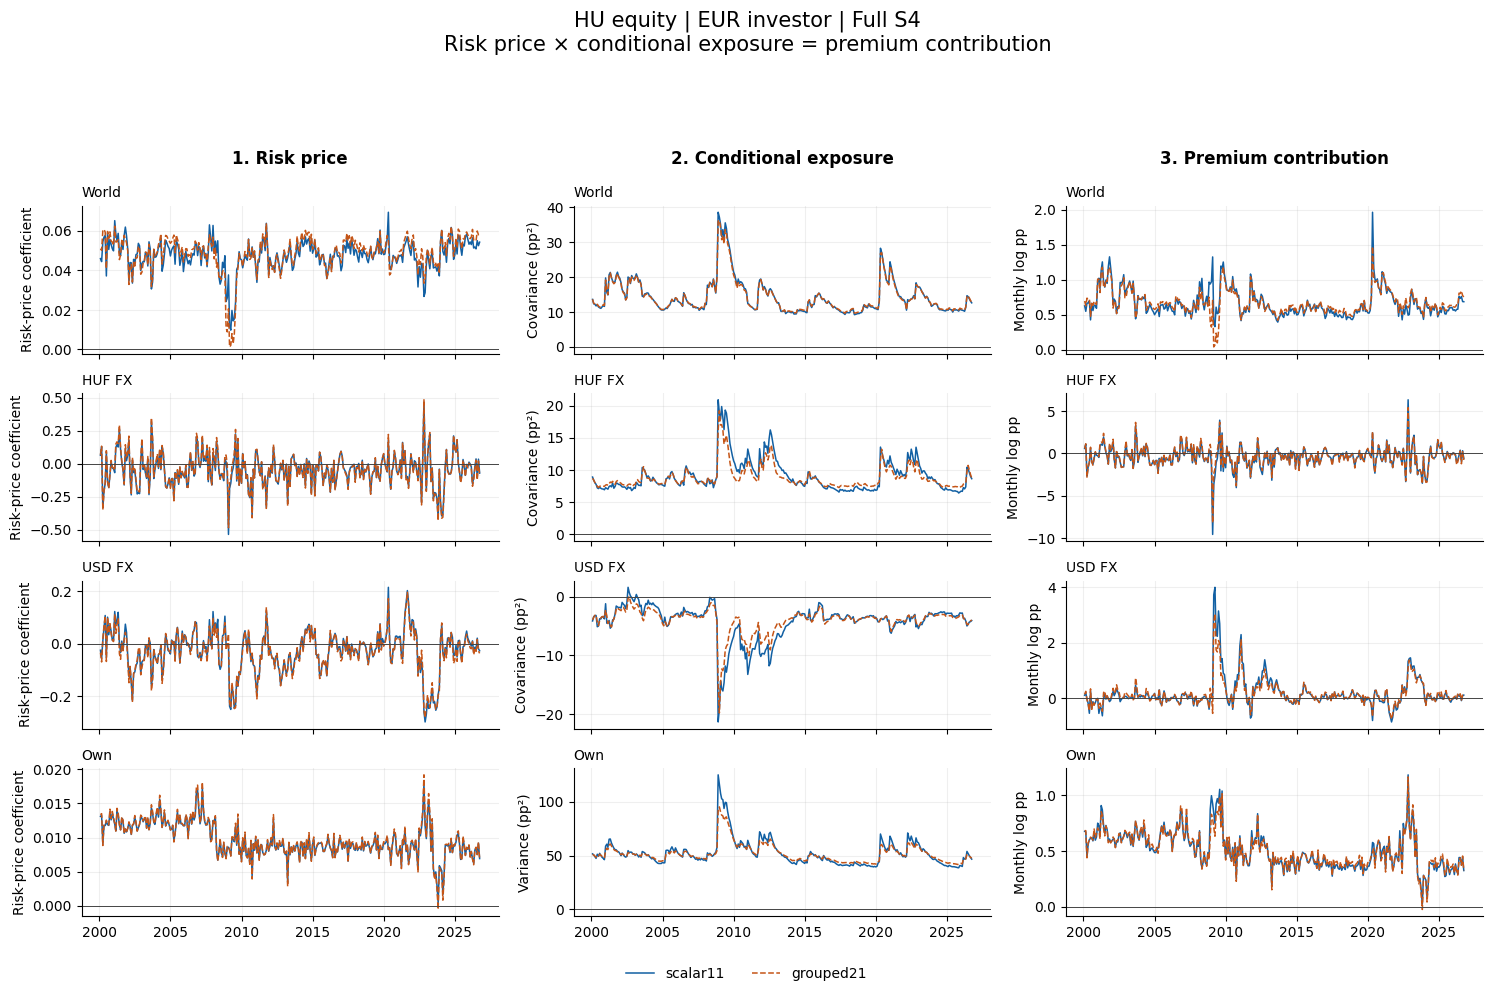

In [3]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2, "font.size": 10})
view = terms.query("specification == @SHOW_SPEC and asset == @SHOW_ASSET")
components = ["World", "HUF FX", "Other FX", "Own"]
images = []
for currency in ["USD", "EUR"]:
    fig, axes = plt.subplots(4, 3, figsize=(15, 10), sharex=True)
    for row, component in enumerate(components):
        for model, color, style in [("scalar11", "#1260a3", "-"), ("grouped21", "#c55517", "--")]:
            part = view.query("perspective == @currency and covariance_model == @model and component == @component")
            dates = pd.PeriodIndex(part["month"], freq="M").to_timestamp("M")
            for col, value in enumerate(["price", "exposure", "contribution"]):
                axes[row, col].plot(dates, part[value], color=color, ls=style, lw=1.1, label=model)
        label = ("EUR FX" if currency == "USD" else "USD FX") if component == "Other FX" else component
        for col in range(3):
            axes[row, col].axhline(0, color="#444444", lw=.7)
            axes[row, col].set_title(label, loc="left", fontsize=10)
        axes[row, 0].set_ylabel("Risk-price coefficient")
        axes[row, 1].set_ylabel("Variance (pp²)" if component == "Own" else "Covariance (pp²)")
        axes[row, 2].set_ylabel("Monthly log pp")
    for ax in axes[-1]:
        ax.xaxis.set_major_locator(mdates.YearLocator(5))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    title = "Full S4" if SHOW_SPEC == "S4" else "FX-only (world/local prices constant)"
    fig.suptitle(f"{SHOW_ASSET} equity | {currency} investor | {title}\nRisk price × conditional exposure = premium contribution", fontsize=15)
    for ax, heading in zip(axes[0], ["1. Risk price", "2. Conditional exposure", "3. Premium contribution"]):
        ax.text(.5, 1.28, heading, transform=ax.transAxes, ha="center", fontsize=12, weight="bold")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
    fig.tight_layout(rect=[0, .035, 1, .92])
    image_path = OUT / f"{SHOW_SPEC}_{SHOW_ASSET}_{currency}_terms.png"
    fig.savefig(image_path, dpi=150)
    images.append(image_path)
    plt.show()
    plt.close(fig)


## Inspect the FX cancellation in specific months

The combined Currency line can conceal large, opposite FX contributions. The example table retains
each price and covariance separately. For the default Hungarian view it includes the 2009 reversal,
April 2020 and the final sample month. These are in-sample fitted quantities, without confidence bands.


In [4]:
groups = ["specification", "perspective", "covariance_model", "asset", "component"]
summary_rows, quadrant_rows, crossing_rows = [], [], []
for key, group in terms.groupby(groups, sort=False):
    info = dict(zip(groups, key))
    summary_rows.append({**info, "months": len(group), "mean_price": group.price.mean(),
        "mean_exposure": group.exposure.mean(), "mean_contribution": group.contribution.mean(),
        "price_negative_pct": 100 * group.price.lt(0).mean(),
        "exposure_negative_pct": 100 * group.exposure.lt(0).mean(),
        "contribution_negative_pct": 100 * group.contribution.lt(0).mean(),
        "price_sign_changes": int(group.price_sign.diff().iloc[1:].ne(0).sum()),
        "exposure_sign_changes": int(group.exposure_sign.diff().iloc[1:].ne(0).sum())})
    for (price_sign, exposure_sign), quadrant in group.groupby(["price_sign", "exposure_sign"]):
        quadrant_rows.append({**info, "price_sign": price_sign, "exposure_sign": exposure_sign,
            "contribution_sign": price_sign * exposure_sign, "months": len(quadrant),
            "percent": 100 * len(quadrant) / len(group)})
    previous = group[["price_sign", "exposure_sign", "contribution_sign"]].shift()
    changed = group.contribution_sign.ne(previous.contribution_sign) & previous.contribution_sign.notna()
    for index in group.index[changed]:
        crossing_rows.append({**info, "month": group.loc[index, "month"],
            "price_sign_changed": bool(group.loc[index, "price_sign"] != previous.loc[index, "price_sign"]),
            "exposure_sign_changed": bool(group.loc[index, "exposure_sign"] != previous.loc[index, "exposure_sign"])})
summary = pd.DataFrame(summary_rows)
quadrants = pd.DataFrame(quadrant_rows)
crossings = pd.DataFrame(crossing_rows)
summary.to_csv(OUT / "term_summary.csv", index=False)
quadrants.to_csv(OUT / "sign_quadrants.csv", index=False)
crossings.to_csv(OUT / "contribution_sign_changes.csv", index=False)

examples = terms.query("specification == @SHOW_SPEC and asset == @SHOW_ASSET and covariance_model == 'grouped21' and component in ['HUF FX', 'Other FX'] and month in ['2009-01', '2009-07', '2020-04', '2026-09']")
display(examples.set_index(["perspective", "month", "component"])[["price", "exposure", "contribution"]].sort_index().round(5))

# Check the exact sign-inversion identity and recheck every input used above before writing provenance.
np.testing.assert_allclose((-terms.price) * (-terms.exposure), terms.contribution, atol=0, rtol=0)
for relative, digest in used.items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == digest
provenance = {"frozen_cutoff": "2026-11-13", "first": str(months[0]), "last": str(months[-1]),
    "observations": len(months), "source_dataset_sha256": LOCK["dataset_sha256"],
    "used_input_sha256": used, "python": sys.executable,
    "specifications": ["S4", "FX"], "perspectives": ["USD", "EUR"],
    "covariance_models": ["scalar11", "grouped21"], "assets": ["HU", "US"],
    "factor_month_products": len(terms), "sign_mismatches": 0,
    "maximum_mean_error": float(audit.max_mean_error.max()),
    "displayed_figures": [p.name for p in images],
    "units": {"price": "matching scaled risk-price coefficient", "exposure": "squared percentage points",
              "contribution": "monthly log percentage points"}}
(OUT / "sign_check_manifest.json").write_text(json.dumps(provenance, indent=2) + "\n")


price  exposure  contribution
perspective month   component                                 
EUR         2009-01 HUF FX    -0.48319  16.99644      -8.21250
                    Other FX   0.03795 -14.65501      -0.55620
            2009-07 HUF FX     0.25918  14.15995       3.67002
                    Other FX  -0.24242  -8.09540       1.96249
            2020-04 HUF FX     0.22142  11.57069       2.56197
                    Other FX   0.17247  -3.90761      -0.67394
            2026-09 HUF FX    -0.08867   8.77768      -0.77831
                    Other FX  -0.03591  -3.96200       0.14229
USD         2009-01 HUF FX    -0.42629  45.47565     -19.38559
                    Other FX   0.37661  25.48084       9.59630
            2009-07 HUF FX     0.11128  35.49621       3.94988
                    Other FX   0.13874  17.80055       2.46959
            2020-04 HUF FX     0.06942  20.97115       1.45584
                    Other FX  -0.33868   9.53955      -3.23083
            2026-09 HUF FX    -0.03000  19.88086      -0.59651
                    Other FX  -0.01716   9.76576      -0.16762

9048

## Summary table

Negative percentages count months using exact unrounded signs. A zero price or covariance would
produce a zero product and is retained separately in `sign_quadrants.csv`. The two FX contributions
are separate here, even when they offset in the chart's combined Currency line. Change `SHOW_SPEC`
or `SHOW_ASSET` above and rerun to inspect another view. The CSVs always contain both specifications,
both investors, both covariance models and both equities.


In [5]:
selected = summary.query("specification == @SHOW_SPEC and asset == @SHOW_ASSET")
table = selected.set_index(["perspective", "covariance_model", "component"])[[
    "mean_price", "mean_exposure", "mean_contribution", "price_negative_pct",
    "exposure_negative_pct", "contribution_negative_pct"]]
display(table.style.format({"mean_price": "{:.5f}", "mean_exposure": "{:.3f}",
    "mean_contribution": "{:+.3f}", "price_negative_pct": "{:.1f}%",
    "exposure_negative_pct": "{:.1f}%", "contribution_negative_pct": "{:.1f}%"}))
display(Markdown(f"**Checks passed:** {len(terms):,} products, zero sign mismatches; maximum saved-mean discrepancy {audit.max_mean_error.max():.2e} monthly log pp. Outputs: `{OUT.relative_to(ROOT)}`."))


**Checks passed:** 20,544 products, zero sign mismatches; maximum saved-mean discrepancy 3.55e-15 monthly log pp. Outputs: `output/18_risk_price_covariance_signs/fixed_2026-11-13`.